# Difference in Difference

## ¿Qué es Diferencia en Diferencias (DiD)?

El método de **Diferencia en Diferencias (Difference-in-Differences o DiD)** es un diseño cuasi-experimental ampliamente utilizado en las ciencias sociales y la economía para estimar efectos causales. Se utiliza principalmente cuando no es posible realizar un experimento aleatorio controlado (A/B testing), pero se dispone de datos observacionales recopilados en múltiples períodos de tiempo.

La idea central de DiD es comparar los cambios a lo largo del tiempo en un grupo que recibe un tratamiento (el **grupo de tratamiento**) con los cambios en un grupo que no lo recibe (el **grupo de control**).

### La Fórmula Básica

El estimador de DiD calcula la diferencia de los resultados antes y después del tratamiento para ambos grupos, y luego resta estas dos diferencias:

$$\text{DiD} = (Y_{\text{Tratamiento, Después}} - Y_{\text{Tratamiento, Antes}}) - (Y_{\text{Control, Después}} - Y_{\text{Control, Antes}})$$

Donde $Y$ representa la variable de resultado de interés (por ejemplo, el consumo de cigarrillos, el salario, etc.).

---

## ¿Por qué es importante en el Análisis Causal?

1. **Control de factores no observados (Efectos Fijos):**
   A diferencia de una simple comparación posterior al tratamiento, DiD elimina el sesgo de selección debido a características omitidas que son constantes en el tiempo (por ejemplo, diferencias culturales o geográficas fijas entre estados o países).

2. **Superación de tendencias temporales globales:**
   Si simplemente comparamos al grupo de tratamiento antes y después, podríamos atribuir erróneamente al tratamiento un cambio que en realidad fue causado por una tendencia general del mercado o factores macroeconómicos. El grupo de control ayuda a capturar y restar esta tendencia temporal común.

3. **El supuesto clave de Tendencias Paralelas (Parallel Trends):**
   La validez de DiD descansa en el supuesto de que, en ausencia del tratamiento, la diferencia promedio entre el grupo de tratamiento y el de control habría permanecido constante a lo largo del tiempo. Validar visual y estadísticamente este supuesto es un paso crítico en cualquier análisis de DiD.

## Descripción del Dataset (`smoking_sc.dta`)

El conjunto de datos cargado proviene de los estudios clásicos de **Control Sintético** y **Diferencia en Diferencias** aplicados a la evaluación de políticas de control del tabaquismo (específicamente inspirados en el impacto de la Proposición 99 en California en 1988).

Este dataset contiene un panel de datos para múltiples estados de EE. UU. a lo largo de varios años (desde 1970 hasta el 2000). A continuación se detallan las variables principales:

*   **`state`**: El estado de Estados Unidos (por ejemplo, Alabama, California, Wyoming, etc.).
*   **`year`**: El año de la observación.
*   **`cigsale`**: Ventas de cigarrillos per cápita (medidas en paquetes por persona al año). Esta suele ser nuestra **variable de resultado ($Y$)**.
*   **`lnincome`**: El logaritmo natural de los ingresos personales per cápita (variable de control macroeconómica).
*   **`beer`**: Consumo de cerveza per cápita (otra variable de control para medir el consumo de otros bienes de consumo regulados o con impuestos).
*   **`age15to24`**: La proporción de la población que se encuentra en el rango de edad de 15 a 24 años (control demográfico).
*   **`retprice`**: El precio minorista promedio de un paquete de cigarrillos en ese estado y año (esencial para comprender la elasticidad precio de la demanda).

### Paso 1. Carga del dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

url = (
    "https://raw.githubusercontent.com/"
    "synth-inference/synthdid/master/"
    "data/california_prop99.csv"
)

df = pd.read_csv(url, sep=";")

df.head()

,State,Year,PacksPerCapita,treated
0,Alabama,1970,89.800003,0
1,Arkansas,1970,100.300003,0
2,Colorado,1970,124.800003,0
3,Connecticut,1970,120.000000,0
4,Delaware,1970,155.000000,0


In [ ]:
df.shape
df.info()
df.isna().sum()
df["State"].nunique()
df["Year"].min(), df["Year"].max()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1209 entries, 0 to 1208
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   State           1209 non-null   object 
 1   Year            1209 non-null   int64  
 2   PacksPerCapita  1209 non-null   float64
 3   treated         1209 non-null   int64  
dtypes: float64(1), int64(2), object(1)
memory usage: 37.9+ KB


(1970, 2000)

In [ ]:
df = df.rename(columns={
    "State": "state",
    "Year": "year",
    "PacksPerCapita": "cigsale"
})


In [ ]:
# Definir grupo tratado y período posterior
df["california"] = (df["state"] == "California").astype(int)
df["post"] = (df["year"] >= 1989).astype(int)

# Indicador de exposición al tratamiento
df["treatment"] = df["california"] * df["post"]

df[[
    "state", "year", "cigsale",
    "california", "post", "treatment"
]].head()

,state,year,cigsale,california,post,treatment
0,Alabama,1970,89.800003,0,0,0
1,Arkansas,1970,100.300003,0,0,0
2,Colorado,1970,124.800003,0,0,0
3,Connecticut,1970,120.000000,0,0,0
4,Delaware,1970,155.000000,0,0,0


In [ ]:
df.columns

Index(['state', 'year', 'cigsale', 'treated', 'california', 'post',
       'treatment'],
      dtype='object')

### Paso 2. Definir el tratamiento
Primero, hay que identificar qué estado recibió la intervención y desde cuándo.
- California es el grupo tratado.
- Los otros 38 estados son el grupo de control.
- El año 1989 marca el comienzo del tratamiento.
- cigsale es el outcome.

In [ ]:
df["california"] = (df["state"] == "California").astype(int)
df["post"] = (df["year"] >= 1989).astype(int)

df["treatment"] = df["california"] * df["post"]

La variable treatment vale 1 únicamente para California desde 1989 en adelante. No confundir california, que identifica al grupo, con post, que identifica al período posterior.


### Paso 3. Explorar los datos
Antes de estimar el efecto, compará la evolución temporal del outcome.

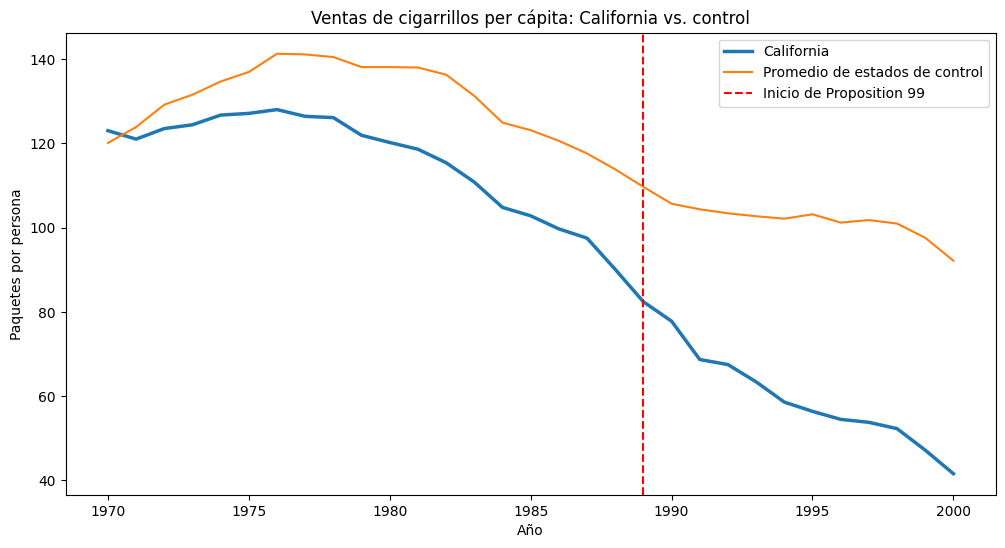

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df[df["state"] == "California"],
    x="year", y="cigsale",
    label="California", linewidth=2.5
)

sns.lineplot(
    data=df[df["state"] != "California"],
    x="year", y="cigsale",
    estimator="mean", errorbar=None,
    label="Promedio de estados de control"
)

plt.axvline(1989, color="red", linestyle="--",
            label="Inicio de Proposition 99")

plt.title("Ventas de cigarrillos per cápita: California vs. control")
plt.xlabel("Año")
plt.ylabel("Paquetes por persona")
plt.legend()
plt.show()

### Paso 4. Calcular el DiD manualmente
Este paso es fundamental para entender qué estima el método.
Primero, calculá el promedio de ventas para cada combinación de grupo y período:

In [ ]:
df["period"] = np.where(df["post"] == 1, "Post", "Pre")

means = (
    df.groupby(["california", "period"])["cigsale"]
    .mean()
    .unstack()
)

means.index = ["Control", "California"]
means

period,Post,Pre
Control,102.058114,130.569529
California,60.350000,116.210526


In [ ]:
change_treated = (
    means.loc["California", "Post"]
    - means.loc["California", "Pre"]
)

change_control = (
    means.loc["Control", "Post"]
    - means.loc["Control", "Pre"]
)

did_manual = change_treated - change_control

print("Cambio en California:", change_treated)
print("Cambio en el control:", change_control)
print("Estimador DiD:", did_manual)

Cambio en California: -55.86052625267543
Cambio en el control: -28.511415169060484
Estimador DiD: -27.349111083614943


La fórmula matemática del estimador es:

$$\widehat{\text{DiD}} = (Y_{T,\text{post}} - Y_{T,\text{pre}}) - (Y_{C,\text{post}} - Y_{C,\text{pre}})$$

Si el estimador es negativo, significa que las ventas de cigarrillos disminuyeron más —o aumentaron menos— en California que en los estados de control, en términos de cambios promedio.

*Nota:* Este cálculo utiliza promedios simples de todos los años pre y post. Es el DiD básico, pero todavía no controla por efectos específicos de cada estado ni por shocks anuales comunes.

### Paso 5. Estimar el DiD con regresión

Ahora estimá el modelo clásico con efectos fijos por estado y año:

$$Y_{it} = \alpha_i + \lambda_t + \beta (D_i \times \text{Post}_t) + \epsilon_{it}$$

Donde:
*   $Y_{it}$: Ventas de cigarrillos per cápita del estado $i$ en el año $t$.
*   $\alpha_i$: Efectos fijos de estado (controlan características invariantes en el tiempo de cada estado).
*   $\lambda_t$: Efectos fijos de año (controlan shocks temporales que afectan a todos los estados por igual).
*   $D_i \times \text{Post}_t$: Variable de interacción del tratamiento (`treatment`), que vale $1$ solo para California en los años posteriores a la política (1989 en adelante).
*   $\beta$: Estimador DiD de interés (mide el impacto causal promedio de la Proposición 99).

Implementación:

In [ ]:
model = smf.ols(
    "cigsale ~ treatment + C(state) + C(year)",
    data=df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": df["state"]}
)

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                cigsale   R-squared:                       0.878
Model:                            OLS   Adj. R-squared:                  0.870
Method:                 Least Squares   F-statistic:                     110.6
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           7.40e-29
Time:                        02:29:03   Log-Likelihood:                -4663.8
No. Observations:                1209   AIC:                             9468.
Df Residuals:                    1139   BIC:                             9824.
Df Model:                          69                                         
Covariance Type:              cluster                                         
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 69, but rank is 30
  res = self.wald_test(


El coeficiente treatment.
- Coeficiente negativo: reducción relativa de las ventas en California.
- Coeficiente positivo: aumento relativo.
- Intervalo de confianza: ayuda a evaluar la incertidumbre de la estimación.


Los efectos fijos de estado controlan diferencias persistentes entre estados, mientras que los efectos fijos de año absorben shocks compartidos por todos ellos.


Una salvedad metodológica: como hay un solo estado tratado, los errores estándar agrupados por estado requieren cautela. Para una inferencia más rigurosa, conviene complementar el análisis con placebos por estado u otros procedimientos apropiados para un único grupo tratado.

### Paso 6. Evaluar tendencias paralelas
El supuesto central de DiD es que, sin la intervención, California habría seguido una evolución comparable a la de su grupo de control.
No alcanza con comparar los niveles de ventas. Tenemos que estudiar las tendencias previas a 1989.
Podemos empezar graficando las diferencias anuales entre California y el promedio del control:

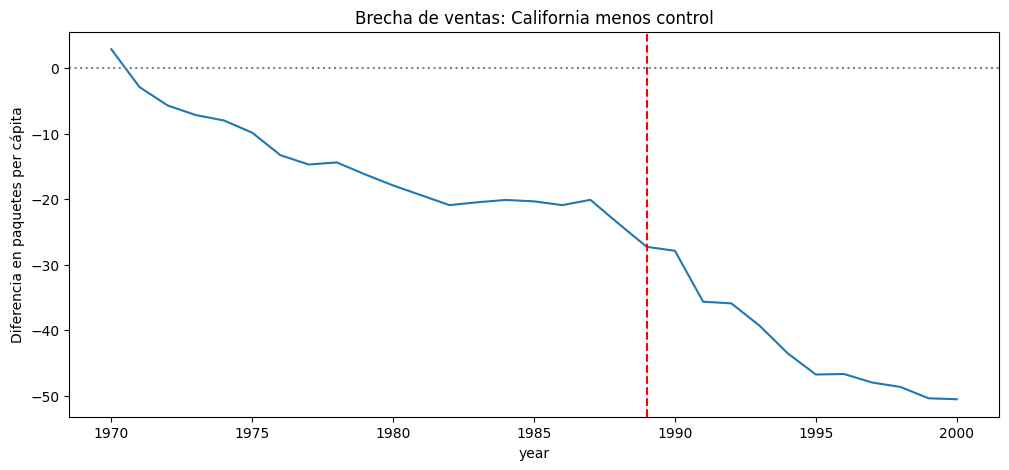

In [ ]:
annual = (
    df.groupby(["year", "california"])["cigsale"]
    .mean()
    .unstack()
)

annual["gap"] = annual[1] - annual[0]

annual["gap"].plot(figsize=(12, 5))
plt.axvline(1989, color="red", linestyle="--")
plt.axhline(0, color="gray", linestyle=":")
plt.title("Brecha de ventas: California menos control")
plt.ylabel("Diferencia en paquetes per cápita")
plt.show()

La brecha puede existir antes de la política; eso no invalida automáticamente DiD. Lo importante es si su evolución previa sugiere tendencias comparables.

### Paso 7. Implementar un estudio de eventos
Para profundizar, estimá efectos asociados a los años relativos al tratamiento. Esto permite examinar los coeficientes previos y la dinámica posterior.

In [ ]:
df["event_time"] = df["year"] - 1989

# Usar 1988 (event_time = -1) como período de referencia.
df["event_time_cat"] = df["event_time"].astype(str)

formula = (
    "cigsale ~ C(state) + C(year) + "
    "C(event_time_cat, Treatment(reference='-1')):california"
)

event_model = smf.ols(formula, data=df).fit(
    cov_type="cluster",
    cov_kwds={"groups": df["state"]}
)

print(event_model.summary())

                            OLS Regression Results                            
Dep. Variable:                cigsale   R-squared:                       0.879
Model:                            OLS   Adj. R-squared:                  0.868
Method:                 Least Squares   F-statistic:                     46.34
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           6.79e-22
Time:                        02:31:38   Log-Likelihood:                -4657.3
No. Observations:                1209   AIC:                             9513.
Df Residuals:                    1110   BIC:                         1.002e+04
Df Model:                          98                                         
Covariance Type:              cluster                                         
                                                                   coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------

/tmp/ipykernel_2528/2362125134.py:11: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  event_model = smf.ols(formula, data=df).fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 99, but rank is 30
  res = self.wald_test(


En esta especificación, los coeficientes de los años anteriores a 1989 se interpretan con respecto a 1988. Los coeficientes previos deberían ser compatibles con cero si no hay evidencia de diferencias en la evolución relativa, aunque esto no prueba el supuesto.

In [ ]:
print("Filas:", len(df))
print("Estados:", df["state"].nunique())
print("Años:", df["year"].min(), "-", df["year"].max())

print("Duplicados estado-año:",
      df.duplicated(["state", "year"]).sum())

print(df[["cigsale", "state", "year"]].isna().sum())

print(df.groupby("california")["state"].nunique())
print(df.groupby(["california", "post"])["cigsale"].mean())

Filas: 1209
Estados: 39
Años: 1970 - 2000
Duplicados estado-año: 0
cigsale    0
state      0
year       0
dtype: int64
california
0    38
1     1
Name: state, dtype: int64
california  post
0           0       130.569529
            1       102.058114
1           0       116.210526
            1        60.350000
Name: cigsale, dtype: float64


In [ ]:
comparison = pd.DataFrame({
    "Método": [
        "DiD manual",
        "Regresión con efectos fijos"
    ],
    "Estimación": [
        did_manual,
        model.params["treatment"]
    ]
})

comparison

,Método,Estimación
0,DiD manual,-27.349111
1,Regresión con efectos fijos,-27.349111


## Interpretación Estadística de la Comparación Final

Al observar los resultados de nuestra tabla comparativa, identificamos dos conclusiones fundamentales para el análisis econométrico:

### 1. Equivalencia Matemática Exacta ($-27.3491$)
Notarás que el estimador del **DiD manual** y el coeficiente de la variable `treatment` en la **Regresión con Efectos Fijos** son exactamente iguales (ambos $-27.3491$).

*   **¿Por qué ocurre esto?** En un diseño de Diferencia en Diferencias balanceado de dos grupos y dos períodos (o agregados pre/post), la estimación de mínimos cuadrados ordinarios (MCO) de la interacción del tratamiento coincide de forma matemática exacta con la doble resta de los promedios muestrales.
*   **¿Cuál es la ventaja de la regresión entonces?** Aunque el valor puntual del impacto estimado sea idéntico, la regresión nos proporciona un marco formal para:
    *   Calcular **errores estándar** válidos para realizar pruebas de hipótesis.
    *   Incorporar controles o covariables adicionales que varían en el tiempo.
    *   Modelar dinámicas temporales complejas (como el estudio de eventos).

### 2. Magnitud y Dirección del Impacto
El valor de **$-27.35$** tiene una interpretación económica directa y de gran escala:
*   **Interpretación:** La introducción de la *Proposición 99* en California redujo el consumo anual de cigarrillos en aproximadamente **27.3 paquetes per cápita** en comparación con la tendencia que habría tenido si no se hubiese implementado la ley (representada por el promedio de los estados de control).
*   Considerando que el consumo promedio previo en California era de $116.2$ paquetes, esta reducción representa una disminución aproximada del **23.5%** en el consumo de tabaco per cápita, un efecto sustancial desde la perspectiva de salud pública.

### 3. Significación Estadística e Inferencia
Si volvemos a examinar la tabla de regresión del **Paso 5**:
*   El coeficiente `treatment` posee un error estándar robusto agrupado por estado (*clustered standard error*) de **$2.849$**.
*   Esto resulta en un estadístico $z = -9.60$ y un p-valor de **$0.000$** ($P > |z|$).
*   **Conclusión:** Podemos rechazar la hipótesis nula de que la política no tuvo impacto con un nivel de confianza superior al $99.9\%$. El intervalo de confianza estimado de $[-32.9, -21.7]$ nos indica que, incluso en el escenario más conservador de la estimación, la reducción fue de al menos $21.7$ paquetes per cápita al año.